In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

# Configuration de l'appareil (GPU si disponible, sinon CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation de l'appareil : {device}")

# Transformation des images en tenseurs
transform = transforms.ToTensor()

# Téléchargement et chargement des ensembles d'entraînement et de test
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=128, shuffle=False)

print(f"Nombre d'images d'entraînement : {len(train_dataset)}")
print(f"Nombre d'images de test : {len(test_dataset)}")

Utilisation de l'appareil : cpu


100.0%
100.0%
100.0%
100.0%


Nombre d'images d'entraînement : 60000
Nombre d'images de test : 10000


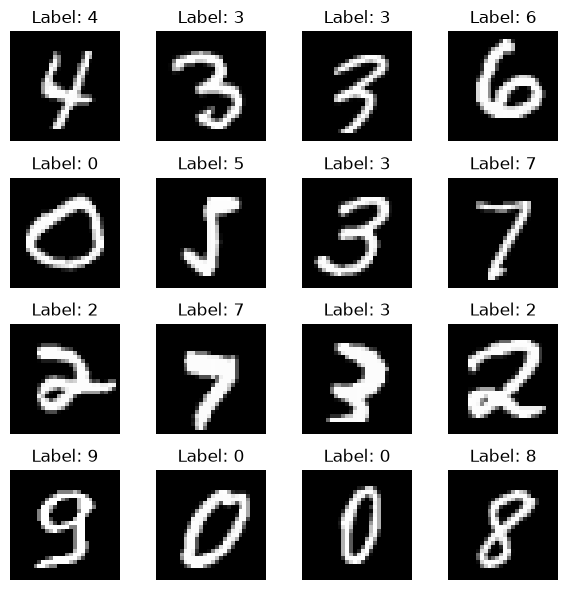

In [3]:
# Récupérer un batch d'images
data_iter = iter(train_loader)
images, labels = next(data_iter)

# Afficher les 16 premières images
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flatten()):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label: {labels[i].item()}")  # <-- Correction ici : set_title au lieu de setTitle
    ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        # Encodeur
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )
        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)
        
        # Décodeur
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar

# Fonction de perte du VAE (Reconstruction Loss + KL Divergence)
def vae_loss_function(x_hat, x, mu, logvar):
    rec_loss = F.binary_cross_entropy(x_hat, x, reduction="sum")
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return rec_loss + kl_loss

In [6]:
latent_dim = 2
vae = VAE(latent_dim=latent_dim).to(device)
optimizer = torch.optim.Adam(vae.parameters(), lr=1e-3)

epochs = 5

vae.train()
for epoch in range(epochs):
    total_loss = 0
    for x, _ in train_loader:
        x = x.to(device)
        
        # Forward pass
        x_hat, mu, logvar = vae(x)
        loss = vae_loss_function(x_hat, x, mu, logvar)
        
        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item()
        
    avg_loss = total_loss / len(train_dataset)
    print(f"Epoch [{epoch+1}/{epochs}] - Loss moyenne: {avg_loss:.4f}")

Epoch [1/5] - Loss moyenne: 194.5173
Epoch [2/5] - Loss moyenne: 166.4164
Epoch [3/5] - Loss moyenne: 161.2036
Epoch [4/5] - Loss moyenne: 158.0470
Epoch [5/5] - Loss moyenne: 156.1141


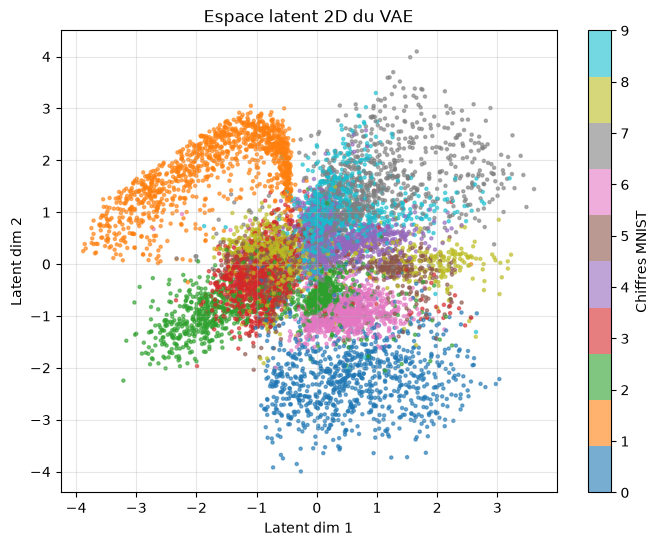

In [7]:
vae.eval()
mu_list = []
label_list = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        mu, _ = vae.encode(x)  # On récupère la moyenne de l'espace latent
        mu_list.append(mu.cpu().numpy())
        label_list.append(y.numpy())

mu_array = np.concatenate(mu_list, axis=0)
label_array = np.concatenate(label_list, axis=0)

# Affichage du nuage de points dans l'espace latent 2D
plt.figure(figsize=(8, 6))
scatter = plt.scatter(mu_array[:, 0], mu_array[:, 1], c=label_array, cmap="tab10", alpha=0.6, s=5)
plt.colorbar(scatter, label="Chiffres MNIST")
plt.title("Espace latent 2D du VAE")
plt.xlabel("Latent dim 1")
plt.ylabel("Latent dim 2")
plt.grid(True, alpha=0.3)
plt.show()

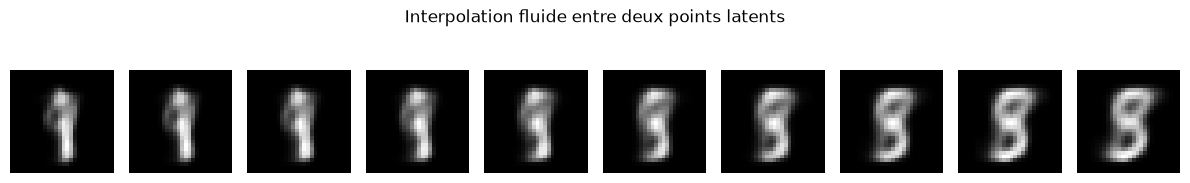

In [8]:
vae.eval()
with torch.no_grad():
    # Définir deux points de départ et d'arrivée aléatoires dans l'espace latent
    z1 = torch.randn(1, latent_dim).to(device)
    z2 = torch.randn(1, latent_dim).to(device)
    
    # Créer 10 étapes d'interpolation entre z1 et z2
    steps = 10
    z_interpolated = torch.cat([z1 + (z2 - z1) * (i / (steps - 1)) for i in range(steps)], dim=0)
    
    # Décoder ces points pour obtenir les images intermédiaires
    decoded_imgs = vae.decode(z_interpolated).cpu()

# Affichage de la séquence d'interpolation
fig, axes = plt.subplots(1, steps, figsize=(12, 2))
for i, ax in enumerate(axes):
    ax.imshow(decoded_imgs[i].squeeze(), cmap="gray")
    ax.axis("off")
plt.suptitle("Interpolation fluide entre deux points latents")
plt.tight_layout()
plt.show()

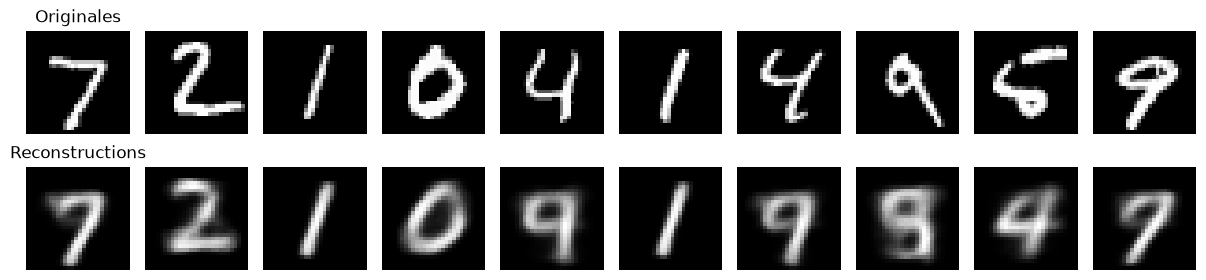

In [9]:
vae.eval()
with torch.no_grad():
    # Prendre un batch d'images de test
    data_iter = iter(test_loader)
    images, _ = next(data_iter)
    images_gpu = images.to(device)
    
    # Reconstruire les images via le VAE
    reconstructed, _, _ = vae(images_gpu)
    reconstructed = reconstructed.cpu()

# Affichage : Ligne du haut = Vraies images, Ligne du bas = Images reconstruites
n = 10
fig, axes = plt.subplots(2, n, figsize=(12, 3))
for i in range(n):
    # Originales
    axes[0, i].imshow(images[i].squeeze(), cmap="gray")
    axes[0, i].axis("off")
    if i == 0: axes[0, i].set_title("Originales")
    
    # Reconstruites
    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray")
    axes[1, i].axis("off")
    if i == 0: axes[1, i].set_title("Reconstructions")

plt.tight_layout()
plt.show()

In [10]:
# Sauvegarde des poids
torch.save(vae.state_dict(), "vae_mnist_weights.pth")
print("Modèle sauvegardé avec succès sous 'vae_mnist_weights.pth' !")

# Pour le recharger plus tard si besoin :
# loaded_vae = VAE(latent_dim=2).to(device)
# loaded_vae.load_state_dict(torch.load("vae_mnist_weights.pth"))
# loaded_vae.eval()

Modèle sauvegardé avec succès sous 'vae_mnist_weights.pth' !


In [11]:
latent_dim_gan = 100

# 1. Le Générateur (transforme du bruit aléatoire en une image de 28x28)
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 784),
            nn.Tanh() # Normalise la sortie entre -1 et 1
        )

    def forward(self, z):
        img = self.net(z)
        return img.view(-1, 1, 28, 28)

# 2. Le Discriminateur (juge si une image est vraie ou fausse)
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 1),
            nn.Sigmoid() # Sortie entre 0 (faux) et 1 (vrai)
        )

    def forward(self, img):
        return self.net(img)

# Instanciation des modèles
generator = Generator(latent_dim_gan).to(device)
discriminator = Discriminator().to(device)

In [12]:
# Hyperparamètres
lr = 0.0002
epochs_gan = 5

criterion_gan = nn.BCELoss()
optimizer_G = torch.optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

for epoch in range(epochs_gan):
    for i, (real_imgs, _) in enumerate(train_loader):
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)
        
        # Étiquettes réelles (1) et fausses (0)
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)
        
        # --- 1. Entraînement du Discriminateur ---
        optimizer_D.zero_grad()
        
        # Perte sur les vraies images
        outputs_real = discriminator(real_imgs)
        loss_real = criterion_gan(outputs_real, real_labels)
        
        # Perte sur les fausses images générées
        z = torch.randn(batch_size, latent_dim_gan).to(device)
        fake_imgs = generator(z)
        outputs_fake = discriminator(fake_imgs.detach())
        loss_fake = criterion_gan(outputs_fake, fake_labels)
        
        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()
        
        # --- 2. Entraînement du Générateur ---
        optimizer_G.zero_grad()
        
        outputs_fake = discriminator(fake_imgs)
        # Le générateur veut que le discriminateur croie que ses fausses images sont vraies (étiquette 1)
        loss_G = criterion_gan(outputs_fake, real_labels)
        
        loss_G.backward()
        optimizer_G.step()
        
    print(f"GAN Epoch [{epoch+1}/{epochs_gan}] | Loss D: {loss_D.item():.4f} | Loss G: {loss_G.item():.4f}")

GAN Epoch [1/5] | Loss D: 0.8258 | Loss G: 2.0338
GAN Epoch [2/5] | Loss D: 0.8494 | Loss G: 2.7726
GAN Epoch [3/5] | Loss D: 0.6784 | Loss G: 1.9498
GAN Epoch [4/5] | Loss D: 0.5652 | Loss G: 2.6088
GAN Epoch [5/5] | Loss D: 0.4772 | Loss G: 3.3978


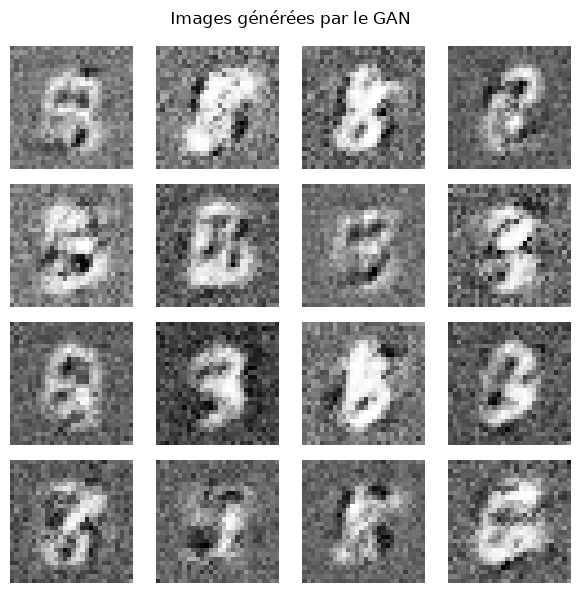

In [13]:
generator.eval()
with torch.no_grad():
    z_test = torch.randn(16, latent_dim_gan).to(device)
    gan_generated = generator(z_test).cpu()

# Affichage
fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for i, ax in enumerate(axes.flatten()):
    # Remise à l'échelle de [-1, 1] vers [0, 1] pour l'affichage
    img = (gan_generated[i].squeeze() + 1) / 2
    ax.imshow(img, cmap="gray")
    ax.axis("off")
plt.suptitle("Images générées par le GAN")
plt.tight_layout()
plt.show()

Epoch [1/5] | Loss D: 0.5644 | Loss G: 3.1240
Epoch [2/5] | Loss D: 0.6419 | Loss G: 2.9258
Epoch [3/5] | Loss D: 0.6672 | Loss G: 2.8387
Epoch [4/5] | Loss D: 0.6538 | Loss G: 2.8270
Epoch [5/5] | Loss D: 0.6352 | Loss G: 2.9624


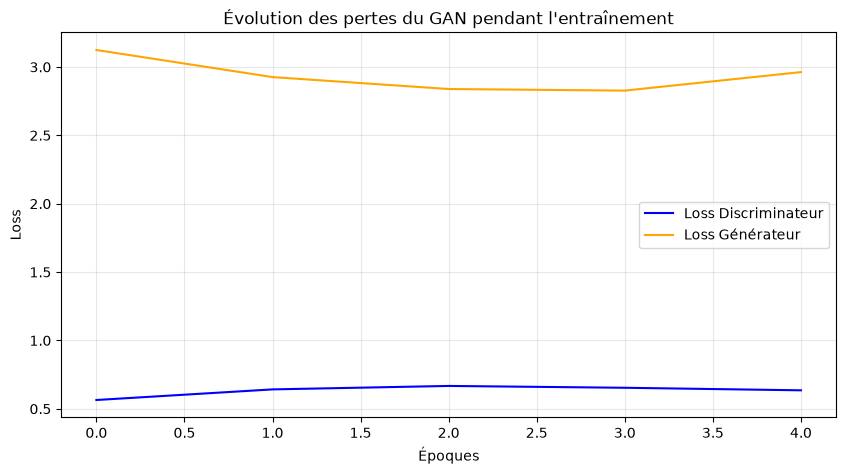

In [14]:
# --- Boucle d'entraînement avec historique des pertes ---
losses_D = []
losses_G = []

for epoch in range(epochs_gan):
    epoch_loss_D = 0
    epoch_loss_G = 0
    
    for i, (real_imgs, _) in enumerate(train_loader):
        batch_size = real_imgs.size(0)
        real_imgs = real_imgs.to(device)
        
        real_labels = torch.ones(batch_size, 1).to(device)
        fake_labels = torch.zeros(batch_size, 1).to(device)
        
        # 1. Entraînement Discriminateur
        optimizer_D.zero_grad()
        outputs_real = discriminator(real_imgs)
        loss_real = criterion_gan(outputs_real, real_labels)
        
        z = torch.randn(batch_size, latent_dim_gan).to(device)
        fake_imgs = generator(z)
        outputs_fake = discriminator(fake_imgs.detach())
        loss_fake = criterion_gan(outputs_fake, fake_labels)
        
        loss_D = loss_real + loss_fake
        loss_D.backward()
        optimizer_D.step()
        
        # 2. Entraînement Générateur
        optimizer_G.zero_grad()
        outputs_fake = discriminator(fake_imgs)
        loss_G = criterion_gan(outputs_fake, real_labels)
        loss_G.backward()
        optimizer_G.step()
        
        epoch_loss_D += loss_D.item()
        epoch_loss_G += loss_G.item()
        
    # Moyenne par époque
    losses_D.append(epoch_loss_D / len(train_loader))
    losses_G.append(epoch_loss_G / len(train_loader))
    print(f"Epoch [{epoch+1}/{epochs_gan}] | Loss D: {losses_D[-1]:.4f} | Loss G: {losses_G[-1]:.4f}")

# --- Tracé des courbes ---
plt.figure(figsize=(10, 5))
plt.plot(losses_D, label="Loss Discriminateur", color="blue")
plt.plot(losses_G, label="Loss Générateur", color="orange")
plt.xlabel("Époques")
plt.ylabel("Loss")
plt.title("Évolution des pertes du GAN pendant l'entraînement")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [15]:
# Sauvegarde des poids du générateur
torch.save(generator.state_dict(), "gan_generator_mnist.pth")
print("Modèle du Générateur GAN sauvegardé avec succès sous 'gan_generator_mnist.pth' !")

Modèle du Générateur GAN sauvegardé avec succès sous 'gan_generator_mnist.pth' !
